In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("PhishFOE_ds.csv", header=0)

Saving PhishFOE_ds.csv to PhishFOE_ds.csv


#XGBOOST(f_classif)

Dimensions du dataset: (101063, 31)
Aperçu des 5 premières lignes:
   IsHTTPS  IsDomainIP  TLD  URLLength  NoOfSubDomain  NoOfDots  \
0        1           0   kr         18              1         2   
1        1           0   ar         23              2         3   
2        1           0   in         27              2         3   
3        1           0  com         24              1         2   
4        1           0  com         22              1         2   

   NoOfObfuscatedChar  NoOfEqual  NoOfQmark  NoOfAmp  ...  HasKeywordPay  \
0                   0          0          0        0  ...              0   
1                   0          0          0        0  ...              1   
2                   0          0          0        0  ...              0   
3                   0          0          0        0  ...              0   
4                   0          0          0        0  ...              0   

   HasKeywordCrypto  NoOfPopup  NoOfiFrame  NoOfImage  NoOfJS  NoOfCSS  \

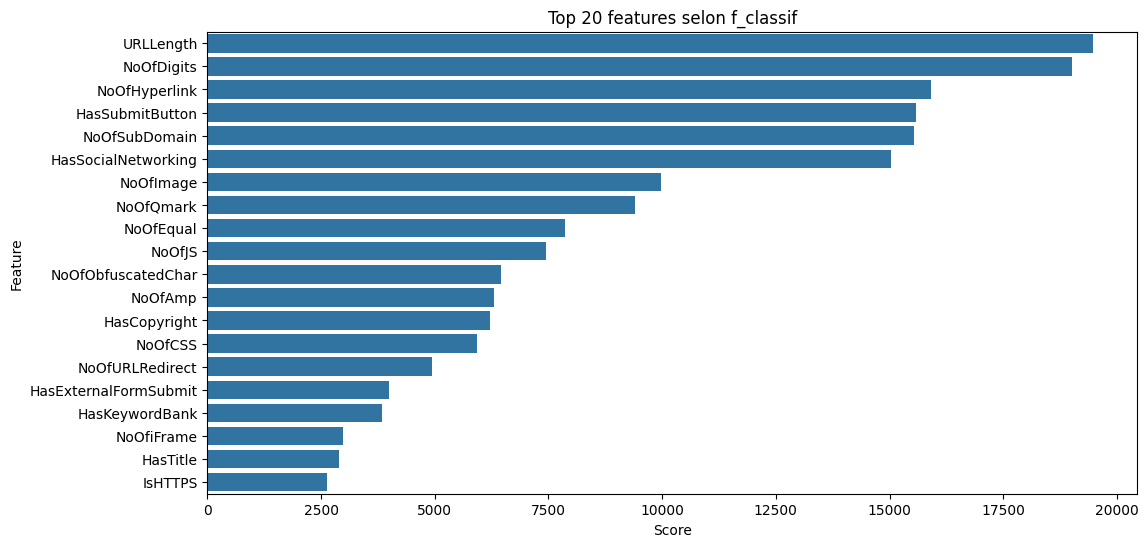

[0]	eval-logloss:0.53403
[1]	eval-logloss:0.42564
[2]	eval-logloss:0.34819
[3]	eval-logloss:0.29151
[4]	eval-logloss:0.24771
[5]	eval-logloss:0.21344
[6]	eval-logloss:0.18611
[7]	eval-logloss:0.16374
[8]	eval-logloss:0.14647
[9]	eval-logloss:0.13286
[10]	eval-logloss:0.11999
[11]	eval-logloss:0.11056
[12]	eval-logloss:0.10260
[13]	eval-logloss:0.09558
[14]	eval-logloss:0.09005
[15]	eval-logloss:0.08525
[16]	eval-logloss:0.08208
[17]	eval-logloss:0.07928
[18]	eval-logloss:0.07715
[19]	eval-logloss:0.07369
[20]	eval-logloss:0.07206
[21]	eval-logloss:0.07070
[22]	eval-logloss:0.06958
[23]	eval-logloss:0.06847
[24]	eval-logloss:0.06541
[25]	eval-logloss:0.06375
[26]	eval-logloss:0.06288
[27]	eval-logloss:0.06224
[28]	eval-logloss:0.06175
[29]	eval-logloss:0.06046
[30]	eval-logloss:0.05888
[31]	eval-logloss:0.05860
[32]	eval-logloss:0.05828
[33]	eval-logloss:0.05804
[34]	eval-logloss:0.05755
[35]	eval-logloss:0.05683
[36]	eval-logloss:0.05666
[37]	eval-logloss:0.05587
[38]	eval-logloss:0.05

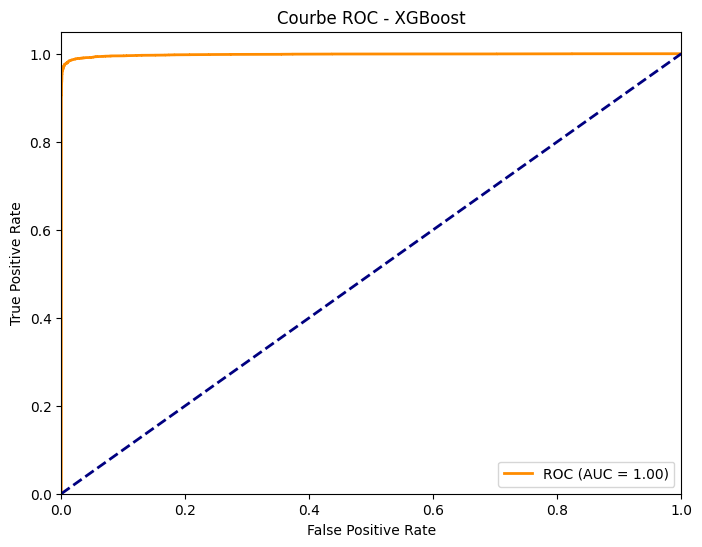


Accuracy sur le jeu de test: 98.54%


In [ ]:
# ---------------------------
# Importation des librairies nécessaires
# ---------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
# Retirer les colonnes non pertinentes (exemple : 'URL')
if 'URL' in df.columns:
    df.drop(columns=['URL'], inplace=True)

# Supprimer les colonnes non numériques
df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

# Vérifier s’il reste bien la colonne cible
if 'label' not in df.columns:
    raise ValueError("La colonne 'label' est absente après nettoyage. Vérifiez le nom ou le contenu du dataset.")

# Affichage de la distribution de la cible
print("\nDistribution initiale des classes :", df['label'].value_counts())

# Séparation X / y
X = df.drop(columns=['label']).values
y = df['label'].values

# ---------------------------
# 2. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X_scaled) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage du dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Sélection des meilleures features
# ---------------------------
selector = SelectKBest(score_func=f_classif, k=20)
selector.fit(X_res, y_res)
X_sel = selector.transform(X_res)
selected_feature_indices = selector.get_support(indices=True)

# Affichage des features sélectionnées
all_features = df.drop(columns=['label']).columns
selected_features = all_features[selected_feature_indices]
print("\nFeatures sélectionnées :", selected_features.tolist())

# Visualisation
feature_scores = selector.scores_
score_df = pd.DataFrame({'Feature': all_features, 'Score': feature_scores})
score_df.sort_values(by='Score', ascending=False, inplace=True)
plt.figure(figsize=(12, 6))
sns.barplot(x="Score", y="Feature", data=score_df.head(20))
plt.title("Top 20 features selon f_classif")
plt.show()

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_sel, y_res, test_size=0.2, random_state=42, stratify=y_res)

# ---------------------------
# 7. Entraînement du modèle XGBoost
# ---------------------------
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,
    'subsample': 0.8,
    'seed': 42
}

num_boost_round = 100
evals = [(dtest, 'eval')]

bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.show()

print("\nAccuracy sur le jeu de test: {:.2f}%".format(accuracy_score(y_test, y_pred) * 100))


Dimensions du dataset: (101063, 30)
Aperçu des 5 premières lignes:
   IsHTTPS  IsDomainIP  URLLength  NoOfSubDomain  NoOfDots  \
0        1           0         18              1         2   
1        1           0         23              2         3   
2        1           0         27              2         3   
3        1           0         24              1         2   
4        1           0         22              1         2   

   NoOfObfuscatedChar  NoOfEqual  NoOfQmark  NoOfAmp  NoOfDigits  ...  \
0                   0          0          0        0           0  ...   
1                   0          0          0        0           0  ...   
2                   0          0          0        0           0  ...   
3                   0          0          0        0           0  ...   
4                   0          0          0        0           2  ...   

   HasKeywordPay  HasKeywordCrypto  NoOfPopup  NoOfiFrame  NoOfImage  NoOfJS  \
0              0                 0       

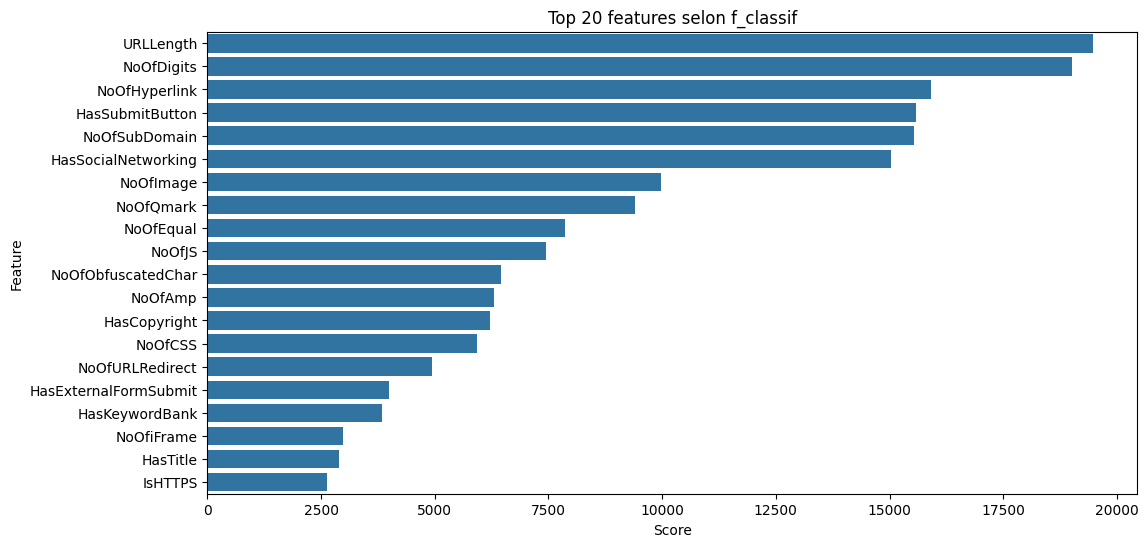

[0]	eval-logloss:0.53403
[1]	eval-logloss:0.42564
[2]	eval-logloss:0.34819
[3]	eval-logloss:0.29151
[4]	eval-logloss:0.24771
[5]	eval-logloss:0.21344
[6]	eval-logloss:0.18611
[7]	eval-logloss:0.16374
[8]	eval-logloss:0.14647
[9]	eval-logloss:0.13286
[10]	eval-logloss:0.11999
[11]	eval-logloss:0.11056
[12]	eval-logloss:0.10260
[13]	eval-logloss:0.09558
[14]	eval-logloss:0.09005
[15]	eval-logloss:0.08525
[16]	eval-logloss:0.08208
[17]	eval-logloss:0.07928
[18]	eval-logloss:0.07715
[19]	eval-logloss:0.07369
[20]	eval-logloss:0.07206
[21]	eval-logloss:0.07070
[22]	eval-logloss:0.06958
[23]	eval-logloss:0.06847
[24]	eval-logloss:0.06541
[25]	eval-logloss:0.06375
[26]	eval-logloss:0.06288
[27]	eval-logloss:0.06224
[28]	eval-logloss:0.06175
[29]	eval-logloss:0.06046
[30]	eval-logloss:0.05888
[31]	eval-logloss:0.05860
[32]	eval-logloss:0.05828
[33]	eval-logloss:0.05804
[34]	eval-logloss:0.05755
[35]	eval-logloss:0.05683
[36]	eval-logloss:0.05666
[37]	eval-logloss:0.05587
[38]	eval-logloss:0.05

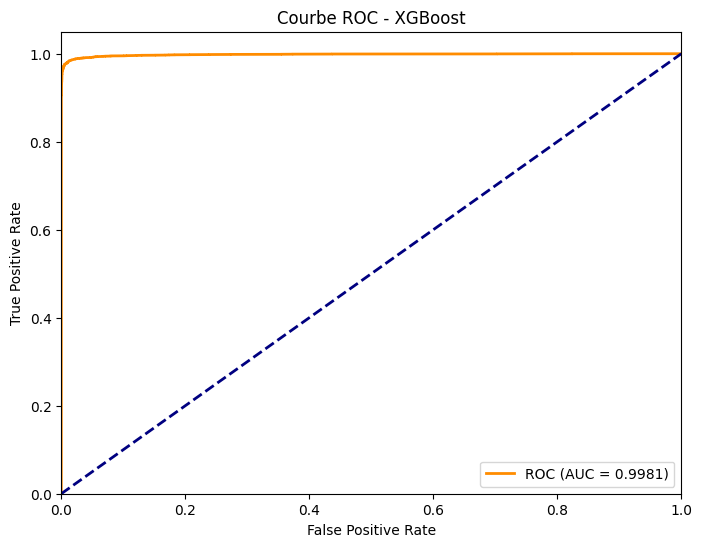


Accuracy sur le jeu de test: 98.5352%


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
# Retirer les colonnes non pertinentes (exemple : 'id' et 'url')
if 'URL' in df.columns:
    df.drop(columns=['URL'], inplace=True)

# Supprimer les colonnes non numériques
df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

# Vérifier s’il reste bien la colonne cible
if 'label' not in df.columns:
    raise ValueError("La colonne 'label' est absente après nettoyage. Vérifiez le nom ou le contenu du dataset.")

# Affichage de la distribution de la cible
print("\nDistribution initiale des classes :", df['label'].value_counts())

# Séparation X / y
X = df.drop(columns=['label']).values
y = df['label'].values


# ---------------------------
# 2. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X_scaled) - np.sum(mask)
    print(f"Pour une contamination de {contamination:.4f}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (ici 0.01)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Sélection des meilleures features avec SelectKBest
# ---------------------------
# Sélectionner les 20 features les plus significatives selon f_classif
selector = SelectKBest(score_func=f_classif, k=20)
selector.fit(X_res, y_res)
X_sel = selector.transform(X_res)
selected_feature_indices = selector.get_support(indices=True)
print("\nIndices des features sélectionnées :", selected_feature_indices)

# (Optionnel) Visualisation des scores des features
feature_scores = selector.scores_
all_features = df.drop(columns=['label']).columns
score_df = pd.DataFrame({'Feature': all_features, 'Score': feature_scores})
score_df.sort_values(by='Score', ascending=False, inplace=True)
plt.figure(figsize=(12,6))
sns.barplot(x="Score", y="Feature", data=score_df.head(20))
plt.title("Top 20 features selon f_classif")
plt.show()

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y_res,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_res)

# ---------------------------
# 7. Préparation pour l'entraînement XGBoost (xgb.train)
# ---------------------------
# Conversion des jeux de données en DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest  = xgb.DMatrix(X_test, label=y_test)

# Meilleurs hyperparamètres trouvés :
# learning_rate = 0.2, max_depth = 7, n_estimators (num_boost_round) = 100, subsample = 0.8
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,          # learning_rate
    'subsample': 0.8,
    'seed': 42
}

num_boost_round = 100

# Entraînement avec early stopping (si aucune amélioration pendant 10 itérations, arrêt)
evals = [(dtest, 'eval')]
bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

# Enregistrement du modèle au format JSON (par exemple)
bst.save_model("xgb_model.json")
print("\nModèle XGBoost enregistré dans 'xgb_model.json'.")

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
# Prédictions sur le jeu de test
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred, digits=4))

# Calcul et affichage de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = {:.4f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.show()

print("\nAccuracy sur le jeu de test: {:.4f}%".format(accuracy_score(y_test, y_pred) * 100))


#xgboost(RFECV)+LSTM

Dimensions du dataset: (101063, 30)
Aperçu des 5 premières lignes:
   IsHTTPS  IsDomainIP  URLLength  NoOfSubDomain  NoOfDots  \
0        1           0         18              1         2   
1        1           0         23              2         3   
2        1           0         27              2         3   
3        1           0         24              1         2   
4        1           0         22              1         2   

   NoOfObfuscatedChar  NoOfEqual  NoOfQmark  NoOfAmp  NoOfDigits  ...  \
0                   0          0          0        0           0  ...   
1                   0          0          0        0           0  ...   
2                   0          0          0        0           0  ...   
3                   0          0          0        0           0  ...   
4                   0          0          0        0           2  ...   

   HasKeywordPay  HasKeywordCrypto  NoOfPopup  NoOfiFrame  NoOfImage  NoOfJS  \
0              0                 0       

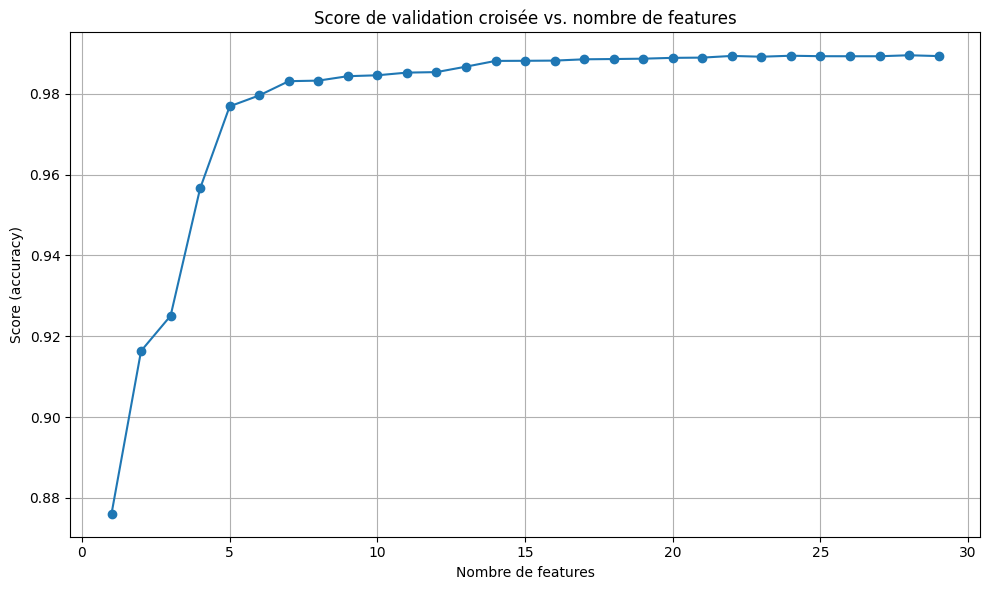


Entraînement XGBoost...
[0]	eval-logloss:0.53279
[1]	eval-logloss:0.42499
[2]	eval-logloss:0.34860
[3]	eval-logloss:0.28806
[4]	eval-logloss:0.24417
[5]	eval-logloss:0.21059
[6]	eval-logloss:0.18134
[7]	eval-logloss:0.15846
[8]	eval-logloss:0.13966
[9]	eval-logloss:0.12488
[10]	eval-logloss:0.11304
[11]	eval-logloss:0.10307
[12]	eval-logloss:0.09532
[13]	eval-logloss:0.08947
[14]	eval-logloss:0.08403
[15]	eval-logloss:0.08015
[16]	eval-logloss:0.07666
[17]	eval-logloss:0.07330
[18]	eval-logloss:0.07108
[19]	eval-logloss:0.06800
[20]	eval-logloss:0.06640
[21]	eval-logloss:0.06429
[22]	eval-logloss:0.06164
[23]	eval-logloss:0.05984
[24]	eval-logloss:0.05783
[25]	eval-logloss:0.05703
[26]	eval-logloss:0.05636
[27]	eval-logloss:0.05562
[28]	eval-logloss:0.05410
[29]	eval-logloss:0.05201
[30]	eval-logloss:0.05168
[31]	eval-logloss:0.05143
[32]	eval-logloss:0.05117
[33]	eval-logloss:0.05059
[34]	eval-logloss:0.04929
[35]	eval-logloss:0.04882
[36]	eval-logloss:0.04803
[37]	eval-logloss:0.047

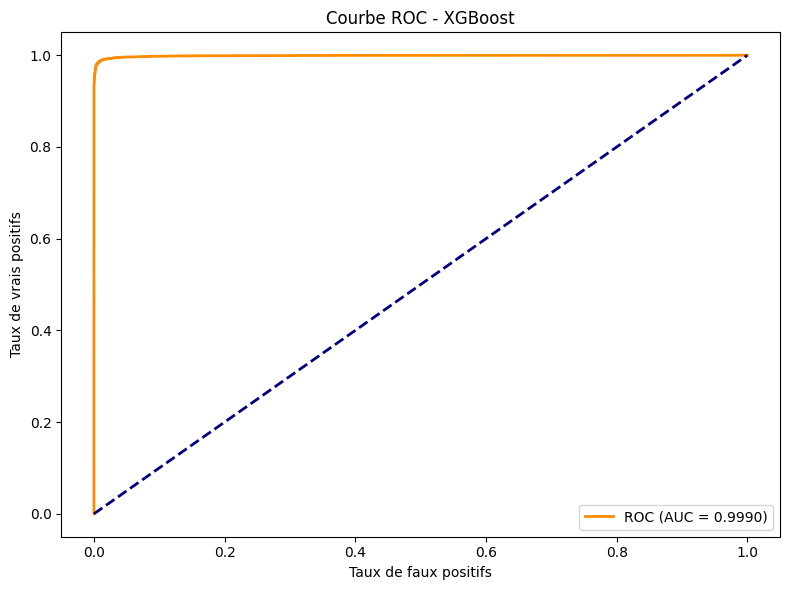

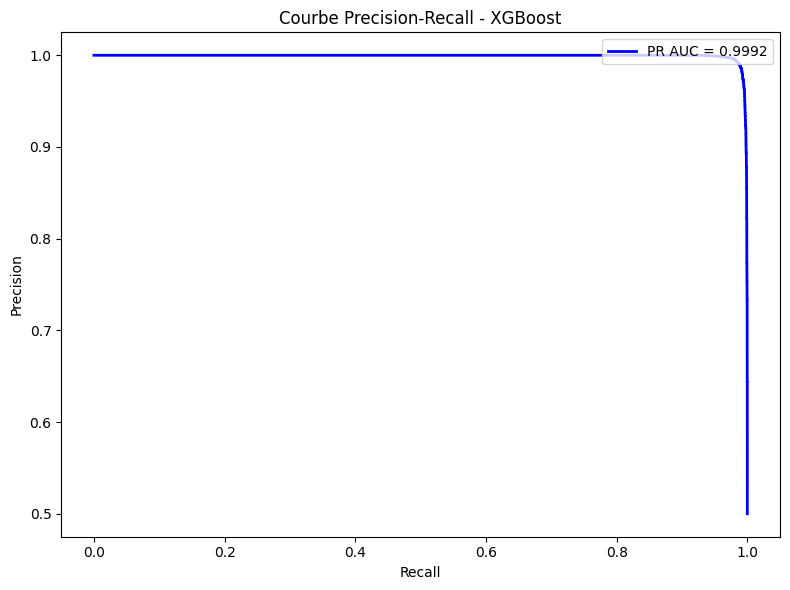

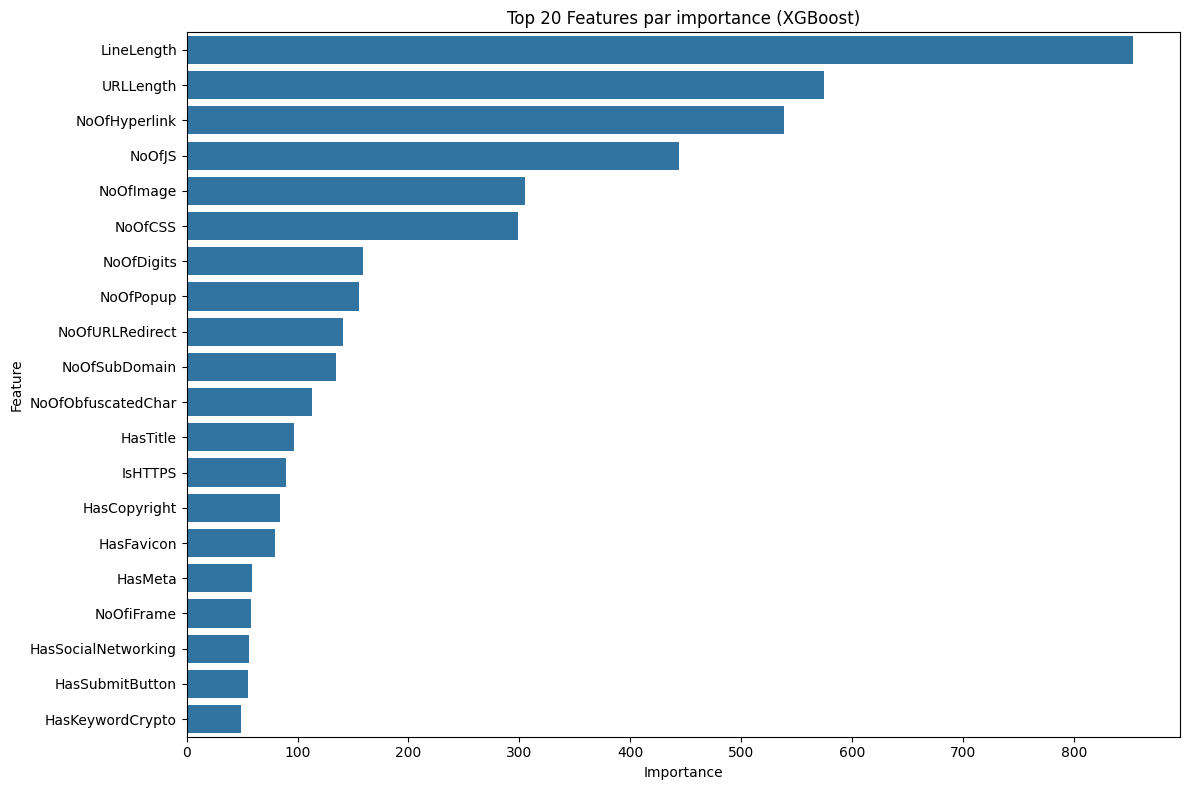


Validation croisée finale...
Scores CV : [0.9887 0.9895 0.988  0.9884 0.9882]
Moyenne : 0.9886
Écart type : 0.0005

COMBINED XGBOOST-LSTM ENSEMBLE MODEL

Generating XGBoost predictions as features...

Combined Model Summary:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1, 28)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 1, 128)    │     80,384 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1, 128)    │        512 │ lstm[0][0]        │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1, 128)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     49,408 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ lstm_1[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 65)        │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,224 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 134,849 (526.75 KB)

 Trainable params: 134,465 (525.25 KB)

 Non-trainable params: 384 (1.50 KB)


Training Combined Model...
Epoch 1/100
1287/1287 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9467 - auc: 0.9831 - loss: 0.1335 - precision: 0.9492 - recall: 0.9433 - val_accuracy: 0.9879 - val_auc: 0.9982 - val_loss: 0.0394 - val_precision: 0.9900 - val_recall: 0.9856 - learning_rate: 0.0010
Epoch 2/100
1287/1287 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.9912 - auc: 0.9987 - loss: 0.0317 - precision: 0.9930 - recall: 0.9894 - val_accuracy: 0.9892 - val_auc: 0.9971 - val_loss: 0.0414 - val_precision: 0.9909 - val_recall: 0.9874 - learning_rate: 0.0010
Epoch 3/100
1287/1287 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9933 - auc: 0.9989 - loss: 0.0244 - precision: 0.9947 - recall: 0.9918 - val_accuracy: 0.9890 - val_auc: 0.9976 - val_loss: 0.0405 - val_precision: 0.9909 - val_recall: 0.9870 - learning_rate: 0.0010
Epoch 4/100
1287/1287 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9936 - auc: 0.9991 - loss: 0.0228 - precision: 0.9948 - recall: 0.9924 - val_accuracy: 0

NameError: name 'confusion_matrix' is not defined

<Figure size 800x600 with 0 Axes>

In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score
from sklearn.feature_selection import RFECV
from sklearn.metrics import precision_recall_curve, average_precision_score

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# Set display precision
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
if 'URL' in df.columns:
    df.drop(columns=['URL'], inplace=True)

df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

if 'label' not in df.columns:
    raise ValueError("La colonne 'label' est absente après nettoyage.")

print("\nDistribution initiale des classes :", df['label'].value_counts())

X = df.drop(columns=['label']).values
y = df['label'].values
feature_names = df.drop(columns=['label']).columns

# ---------------------------
# 2. Normalisation des features
# ---------------------------
print("\nApplication de transformations pour normaliser les distributions...")
power_transformer = PowerTransformer(method='yeo-johnson')
X_transformed = power_transformer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)
print("Transformations appliquées.")

# ---------------------------
# 3. Détection d'anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    print(f"Contamination {contamination:.4f} -> {len(X_scaled) - np.sum(mask)} points supprimés")

chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Sélection de features avec RFECV
# ---------------------------
base_estimator = RandomForestClassifier(n_estimators=100, random_state=42)
rfecv = RFECV(estimator=base_estimator,
              step=1,
              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
              scoring='accuracy',
              n_jobs=-1,
              verbose=1)

print("\nSélection des features en cours...")
rfecv.fit(X_res, y_res)

print(f"\nNombre optimal de features: {rfecv.n_features_}")
print(f"Score CV optimal: {rfecv.cv_results_['mean_test_score'][rfecv.n_features_ - 1]:.4f}")

selected_features_mask = rfecv.support_
selected_feature_names = feature_names[selected_features_mask]

print("\nFeatures sélectionnées:")
for i, feature in enumerate(selected_feature_names):
    print(f"{i+1}. {feature}")

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'], marker='o')
plt.title("Score de validation croisée vs. nombre de features")
plt.xlabel("Nombre de features")
plt.ylabel("Score (accuracy)")
plt.grid(True)
plt.tight_layout()
plt.show()

X_sel = rfecv.transform(X_res)

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y_res, test_size=0.2, random_state=42, stratify=y_res)

# ---------------------------
# 7. Préparation XGBoost
# ---------------------------
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,
    'subsample': 0.8,
    'seed': 42
}
num_boost_round = 100
evals = [(dtest, 'eval')]

print("\nEntraînement XGBoost...")
bst = xgb.train(params, dtrain, num_boost_round=num_boost_round, evals=evals, early_stopping_rounds=10)

print(f"\nMeilleure itération: {bst.best_iteration}")
print(f"Meilleur score: {bst.best_score:.4f}")

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred, digits=4))

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
pr_auc = average_precision_score(y_test, y_proba)

print(f"Précision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"PR AUC    : {pr_auc:.4f}")

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Courbe Precision-Recall
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall_vals, precision_vals, color='blue', lw=2, label=f'PR AUC = {pr_auc:.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Courbe Precision-Recall - XGBoost')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# ---------------------------
# 9. Importance des features
# ---------------------------
if hasattr(bst, 'get_score'):
    importance_dict = bst.get_score(importance_type='weight')
    importance_list = [
        (selected_feature_names[i], importance_dict.get(f'f{i}', 0))
        for i in range(X_sel.shape[1])
    ]
    importance_list.sort(key=lambda x: x[1], reverse=True)
    importance_df = pd.DataFrame(importance_list, columns=['Feature', 'Importance'])

    plt.figure(figsize=(12, 8))
    sns.barplot(x='Importance', y='Feature', data=importance_df.head(20))
    plt.title('Top 20 Features par importance (XGBoost)')
    plt.tight_layout()
    plt.show()

# ---------------------------
# 10. Validation croisée finale
# ---------------------------
print("\nValidation croisée finale...")

xgb_clf = xgb.XGBClassifier(
    max_depth=7,
    learning_rate=0.2,
    n_estimators=bst.best_iteration if hasattr(bst, 'best_iteration') else num_boost_round,
    subsample=0.8,
    random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_clf, X_sel, y_res, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"Scores CV : {cv_scores}")
print(f"Moyenne : {cv_scores.mean():.4f}")
print(f"Écart type : {cv_scores.std():.4f}")

# ---------------------------
# 11. COMBINED XGBOOST-LSTM MODEL
# ---------------------------
print("\n" + "="*80)
print("COMBINED XGBOOST-LSTM ENSEMBLE MODEL")
print("="*80)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Get XGBoost predictions as additional features
print("\nGenerating XGBoost predictions as features...")
xgb_train_probs = bst.predict(dtrain).reshape(-1, 1)
xgb_test_probs = bst.predict(dtest).reshape(-1, 1)

# Reshape data for LSTM (samples, timesteps, features)
X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])  # (samples, 1 timestep, n_features)
X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

# Combined Model Architecture
def build_combined_model(input_shape):
    # LSTM Branch
    lstm_input = Input(shape=input_shape)
    x = LSTM(128, return_sequences=True)(lstm_input)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = LSTM(64)(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    # XGBoost Branch (pre-computed probabilities)
    xgb_input = Input(shape=(1,))

    # Combined layers
    combined = Concatenate()([x, xgb_input])
    x = Dense(64, activation='relu')(combined)
    x = Dropout(0.2)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=[lstm_input, xgb_input], outputs=output)

# Build and compile
combined_model = build_combined_model((1, X_train.shape[1]))
combined_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

print("\nCombined Model Summary:")
combined_model.summary()

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6)

# Train the combined model
print("\nTraining Combined Model...")
history = combined_model.fit(
    [X_train_lstm, xgb_train_probs], y_train,
    validation_data=([X_test_lstm, xgb_test_probs], y_test),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# ---------------------------
# 12. COMBINED MODEL EVALUATION
# ---------------------------
print("\n" + "="*80)
print("COMBINED MODEL EVALUATION")
print("="*80)

# Evaluate
test_results = combined_model.evaluate([X_test_lstm, xgb_test_probs], y_test, verbose=0)
print(f"\nTest Loss: {test_results[0]:.4f}")
print(f"Test Accuracy: {test_results[1]:.4f}")
print(f"Test Precision: {test_results[2]:.4f}")
print(f"Test Recall: {test_results[3]:.4f}")
print(f"Test AUC: {test_results[4]:.4f}")

# Predictions
y_pred_combined = (combined_model.predict([X_test_lstm, xgb_test_probs]) > 0.5).astype(int)

# Classification Report
print("\n--- Combined Model Classification Report ---")
print(classification_report(y_test, y_pred_combined, digits=4))



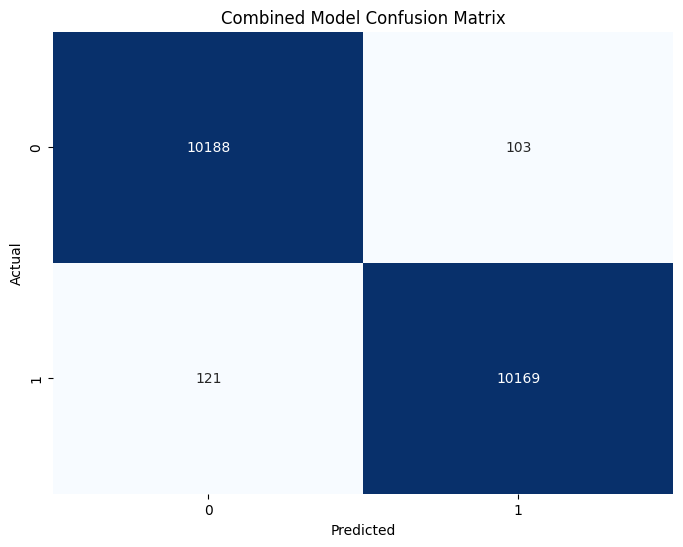

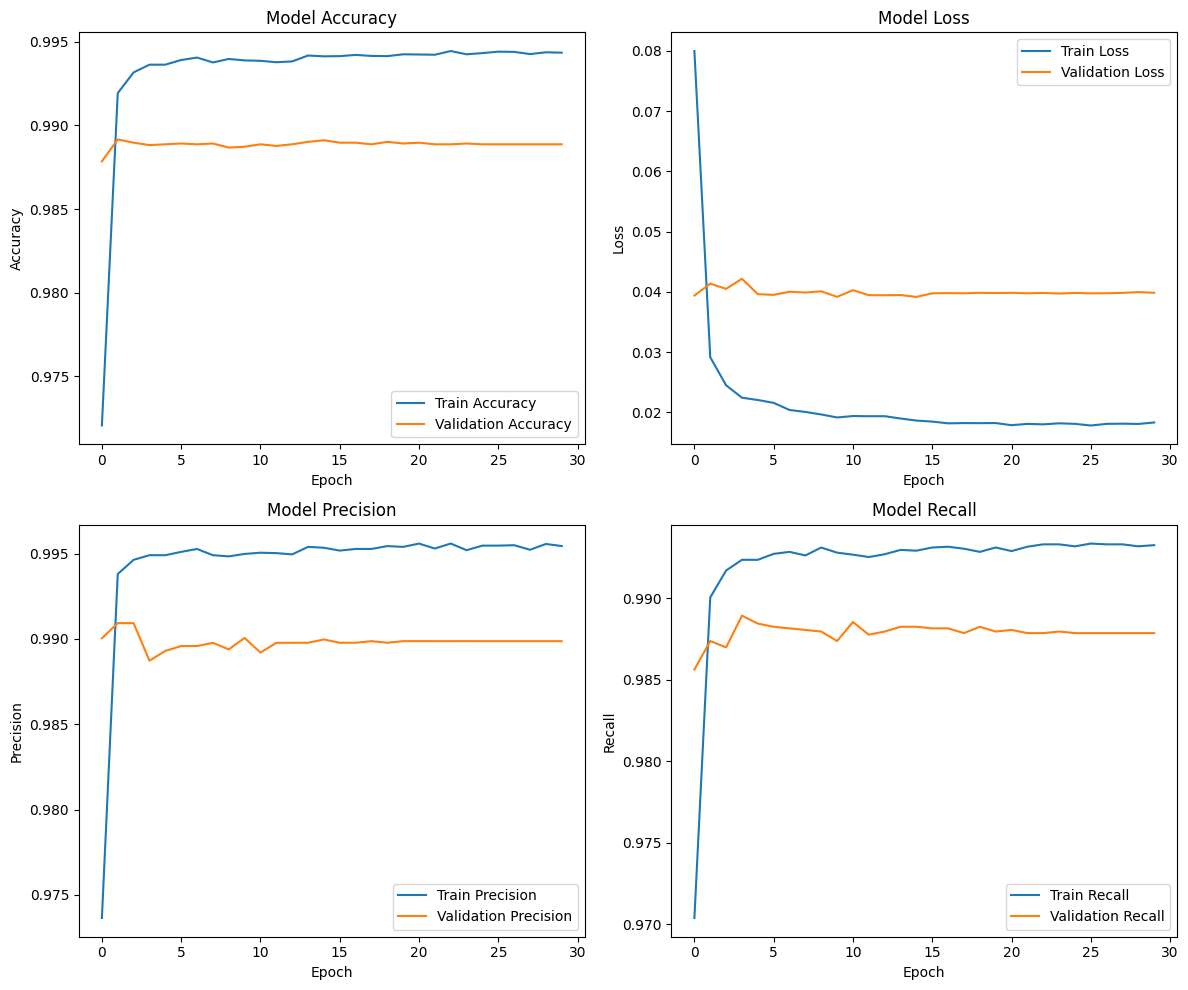

In [ ]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_combined),
            annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Combined Model Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Training History Plots
plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history.history['precision'], label='Train Precision')
plt.plot(history.history['val_precision'], label='Validation Precision')
plt.title('Model Precision')
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history.history['recall'], label='Train Recall')
plt.plot(history.history['val_recall'], label='Validation Recall')
plt.title('Model Recall')
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
print("\nSauvegarde du modèle XGBoost...")
bst.save_model('xgboost_model.txt')
print("Modèle sauvegardé sous 'xgboost_model.txt'")

print("\n" + "="*80)
print("ANALYSE TERMINÉE")
print("="*80)

from sklearn.metrics import (
    classification_report, roc_curve, auc, accuracy_score,
    precision_recall_curve, confusion_matrix, average_precision_score,
    f1_score, precision_score,recall_score
)
import pickle

# Calculate final metrics
final_metrics = {
    'confusion_matrix': confusion_matrix(y_test, y_pred),
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'fpr': fpr,
    'tpr': tpr,
    'roc_auc': roc_auc,
    'precision_curve': precision,
    'recall_curve': recall,
    'pr_auc': pr_auc,
    'feature_importance': bst.get_score(importance_type='weight'),
    'feature_names': selected_feature_names
}

# Save model, preprocessors, and metrics
model_data = {
    'model': bst,
    'power_transformer': power_transformer,
    'scaler': scaler,
    'selected_features_mask': selected_features_mask,
    'selected_feature_names': selected_feature_names,
    'feature_names': feature_names,
    'metrics': final_metrics
}
with open('xgboost_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)


Sauvegarde du modèle XGBoost...
Modèle sauvegardé sous 'xgboost_model.txt'

ANALYSE TERMINÉE


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:40:43] WARNING: /workspace/src/c_api/c_api.cc:1374: Saving model in the UBJSON format as default.  You can use file extension: `json`, `ubj` or `deprecated` to choose between formats.
  warnings.warn(smsg, UserWarning)
